<a href="https://colab.research.google.com/github/MarinaAcosta20/MarinaAcosta20/blob/main/Exercicios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Primeiro exercício, abordando temas:

Bloco 1: Construindo um Neurônio Artificial do Zero (Numpy)

Bloco 2: Avaliação do Modelo e Métricas Biomédicas

Instalando e importando bibliotecas

In [ ]:
!pip install -q shap matplotlib seaborn scikit-learn torch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
import shap

# Configuração de estilo visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

print("✅ Bibliotecas carregadas com sucesso!")

✅ Bibliotecas carregadas com sucesso!


O NEURÔNIO ARTIFICIAL DO ZERO (NUMPY)

Objetivo: Compreender a matemática do modelo sem abstrações de bibliotecas.

A equação do neurônio: y = sigmoide(W . X + b)

In [ ]:
def sigmoide(z):
    """Função de Ativação Sigmóide."""
    return 1 / (1 + np.exp(-z))

def neuronio_artificial(X, W, b):
    """
    Realiza o Forward Pass de um único neurônio artificial.
    X: Vetor de características (inputs)
    W: Vetor de pesos (weights)
    b: Viés (bias)
    """
    # 1. Combinação linear (soma ponderada)
    z = np.dot(X, W) + b
    # 2. Aplicação da função de ativação
    a = sigmoide(z)
    return a

# --- EXEMPLO PRÁTICO ---
# Suponha 3 variáveis de um exame de sangue: [Glicose, Colesterol, Pressão]
exame_paciente = np.array([140, 220, 130])

# Pesos atribuídos arbitrariamente pela rede e viés
pesos = np.array([0.03, 0.01, 0.02])
vies = -5.0

# Execução do neurônio
probabilidade = neuronio_artificial(exame_paciente, pesos, vies)
print(f"[BLOCO 1] Probabilidade de Risco Prevista: {probabilidade:.4f} ({probabilidade*100:.2f}%)")

# ------------------------------------------------------------------------------
# EXERCÍCIO 1
# ------------------------------------------------------------------------------
# Modifique os pesos para dar mais importância à Glicose (índice 0) do paciente
# e recalcule a saída do neurônio.
# ------------------------------------------------------------------------------

[BLOCO 1] Probabilidade de Risco Prevista: 0.9820 (98.20%)


AVALIAÇÃO DE DESEMPENHO E METRICAS



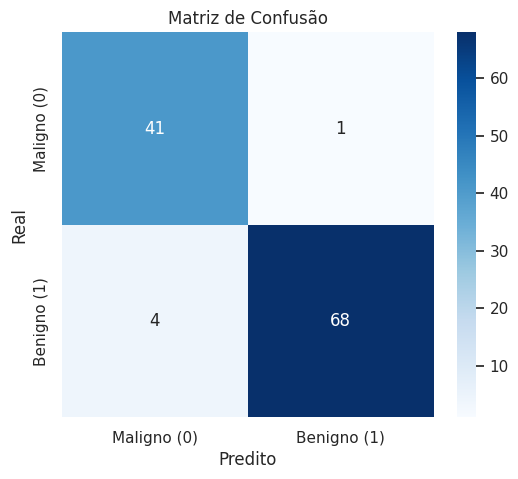

--- MÉRICA DE DESEMPENHO (CLASSE MALIGNA - 0) ---
Acurácia Geral: 0.9561
Sensibilidade (Recall): 0.9762
Precisão: 0.9111
F1-Score: 0.9425


In [ ]:
# ==============================================================================
# BLOCO 2: TREINANDO UMA REDE NEURAL EM PYTORCH (DATASET BIOMÉDICO)
# ==============================================================================
# Dataset: Wisconsin Breast Cancer (Classificação Binária de Tumores)

# 1. Carregamento e Preparação dos Dados
data = load_breast_cancer()
X = data.data
y = data.target  # 0 = Maligno, 1 = Benigno

# Divisão Treino / Teste (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Normalização Z-score (Crucial para Redes Neurais!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Conversão para tensores do PyTorch
X_train_t = torch.FloatTensor(X_train_scaled)
y_train_t = torch.FloatTensor(y_train).unsqueeze(1)
X_test_t = torch.FloatTensor(X_test_scaled)
y_test_t = torch.FloatTensor(y_test).unsqueeze(1)

# 2. Definição da Arquitetura do MLP
class MLPBiomedico(nn.Module):
    def __init__(self, input_dim):
        super(MLPBiomedico, self).__init__()
        # Camada Oculta 1: Entrada -> 16 neurônios
        self.fc1 = nn.Linear(input_dim, 16)
        self.relu1 = nn.ReLU()
        # Camada Oculta 2: 16 -> 8 neurônios
        self.fc2 = nn.Linear(16, 8)
        self.relu2 = nn.ReLU()
        # Camada de Saída: 8 -> 1 neurônio (Saída Binária)
        self.out = nn.Linear(8, 1)
        self.sigmoide = nn.Sigmoid()

    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.sigmoide(self.out(x))
        return x

input_dim = X_train.shape[1]
modelo = MLPBiomedico(input_dim)

# 3. Definição da Perda (Loss) e Otimizador
criterion = nn.BCELoss()  # Binary Cross Entropy Loss
optimizer = optim.Adam(modelo.parameters(), lr=0.01)

# 4. Loop de Treinamento
epochs = 100
historico_loss = []

for epoch in range(epochs):
    modelo.train()
    optimizer.zero_grad()            # Zera os gradientes
    outputs = modelo(X_train_t)      # Forward Pass
    loss = criterion(outputs, y_train_t) # Cálculo da Perda
    loss.backward()                  # Backpropagation
    optimizer.step()                 # Atualização dos pesos

    historico_loss.append(loss.item())

#print(f"[BLOCO 2] Treinamento Concluído! Perda Final: {historico_loss[-1]:.4f}")

# Gráfico de evolução da perda
#plt.figure()
#plt.plot(historico_loss, color='darkred', lw=2)
#plt.title('Curva de Aprendizado (Loss x Épocas)')
#plt.xlabel('Época')
#plt.ylabel('Loss (BCE)')
#plt.show()

modelo.eval()
with torch.no_grad():
    y_pred_probs = modelo(X_test_t).numpy()
    y_pred = (y_pred_probs >= 0.5).astype(int)

# 1. Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Maligno (0)', 'Benigno (1)'],
            yticklabels=['Maligno (0)', 'Benigno (1)'])
plt.title('Matriz de Confusão')
plt.xlabel('Predito')
plt.ylabel('Real')
plt.show()

# 2. Métricas Quantitativas
sensibilidade = recall_score(y_test, y_pred, pos_label=0) # Foco na classe maligna
precisao = precision_score(y_test, y_pred, pos_label=0)
f1 = f1_score(y_test, y_pred, pos_label=0)
acuracia = accuracy_score(y_test, y_pred)

print(f"--- MÉRICA DE DESEMPENHO (CLASSE MALIGNA - 0) ---")
print(f"Acurácia Geral: {acuracia:.4f}")
print(f"Sensibilidade (Recall): {sensibilidade:.4f}")
print(f"Precisão: {precisao:.4f}")
print(f"F1-Score: {f1:.4f}")

# 3. Curva ROC e AUC
#fpr, tpr, _ = roc_curve(y_test, 1 - y_pred_probs, pos_label=0)
#roc_auc = auc(fpr, tpr)

#plt.figure()
#plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.3f})')
#plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
#plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
#plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)')
#plt.title('Curva ROC - Detecção de Câncer Maligno')
#plt.legend(loc="lower right")
#plt.show()

# ------------------------------------------------------------------------------
# EXERCÍCIO 2
# ------------------------------------------------------------------------------
# No contexto clínico do diagnóstico de câncer, qual metrica é mais crítica:
# Sensibilidade (De todos os positivos que realmente existiam, quantos o modelo
# conseguiu encontrar) ou Precisão (Dos positivos que o modelo apontou, quantos
# eram de fato positivos)? Justifique considerando os riscos de Falsos Negativos
# ------------------------------------------------------------------------------